# EDA on OntoNotes v5 NER dataset

![Python](https://img.shields.io/static/v1?label=Python&message=3.9&color=red&style=flat)
<!-- ![Pandas](https://img.shields.io/static/v1?label=Pandas&message=1.4&color=blue&style=flat) -->
<!-- ![Matplotlib](https://img.shields.io/static/v1?label=Matplotlib&message=3.5&color=green&style=flat) -->

A data analysis and exploration is important part of any machine learning task to understand about dataset in various aspects. In this notebook we will see how to explore and understand dataset by analysis and plotting.

The following analysis will be covered:
1. Word level analysis
2. Sentence level analysis
3. NER tag analysis
4. NER tag word cloud

### Import Libraries

In [1]:
import re
from collections import Counter
import itertools

import matplotlib.pyplot as plt

import numpy as np
import pandas as pd

import plotly.express as px
from plotly.subplots import make_subplots

from wordcloud import WordCloud

### Load Dataset

In [2]:
def format_data(lines):
    word_ls, tag_ls = [], []
    for _l in lines:
        _word, _tag = _l.strip().split("\t")
        word_ls.append(_word)
        tag_ls.append(_tag)
    return word_ls, tag_ls

def load_data(path):
    with open(path, 'r') as _file:
        all_data = []
        for i, (x, y) in enumerate(itertools.groupby(_file, lambda x : x == '\n')):
            if x: continue
            y = format_data(y)
            all_data.append(y)
        df = pd.DataFrame(all_data, columns=["words", "tags"])
        return df 

In [3]:
train_df = load_data('data/ontonotes/train.conll')
test_df = load_data('data/ontonotes/test.conll')

In [4]:
train_df.shape, test_df.shape

((75187, 2), (9479, 2))

We have total `75K` sample in training set and `10K` sample in testing set.

In [5]:
train_df.head()

,words,tags
0,"[What, kind, of, memory, ?]","[O, O, O, O, O]"
1,"[We, respectfully, invite, you, to, watch, a, ...","[O, O, O, O, O, O, O, O, O, O, B-ORG, I-ORG, O]"
2,"[WW, II, Landmarks, on, the, Great, Earth, of,...","[B-WORK_OF_ART, I-WORK_OF_ART, I-WORK_OF_ART, ..."
3,"[Standing, tall, on, Taihang, Mountain, is, th...","[O, O, O, B-LOC, I-LOC, O, B-WORK_OF_ART, I-WO..."
4,"[It, is, composed, of, a, primary, stele, ,, s...","[O, O, O, O, O, O, O, O, O, O, O, O, O, O, O, ..."


### EDA

#### Word level analysis

In [6]:
words_flatten = np.hstack(train_df.words.values)
len(words_flatten)

1299312

In [7]:
word_len = np.array([len(x) for x in words_flatten])

In [8]:
word_len.min(), word_len.max(), word_len.mean(), np.median(word_len)

(1, 82, 4.155406091839374, 4.0)

In [9]:
(word_len <= 10).sum() / len(word_len)

0.978580202445602

In [10]:
(word_len <= 5).sum() / len(word_len)

0.7453837107638505

In [11]:
(word_len > 10).sum()

27831

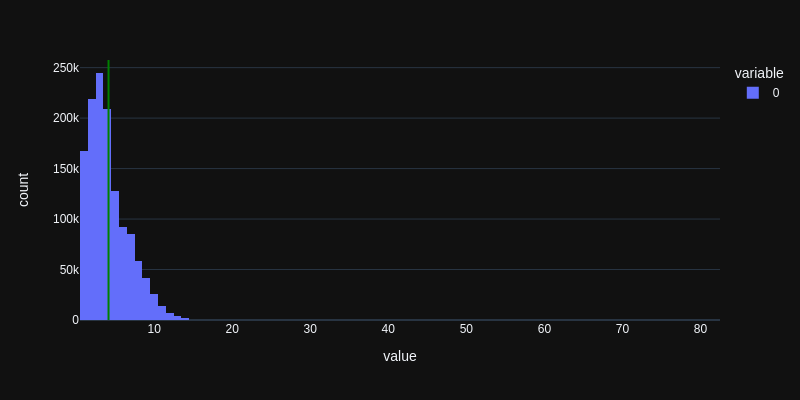

In [12]:
fig = px.histogram(word_len, template='plotly_dark')
fig.update_layout(autosize=False, width=800, height=400)
fig.add_vline(x=word_len.mean(), line_color="green")
fig.show('png')

- 12 millions of words
- On an avergage near 220k words is 3 to 4 characters long. 
- 74% of words is less than 5 characters long. 
- 97% of words is less than 10 characters long.
- 27K of words is longer that 10 characters.

#### Length of the sentences

In [13]:
train_df['total_words'] = train_df.words.apply(lambda x : len(x))

In [14]:
total_word_mean = np.mean(train_df.total_words)
total_word_median = np.median(train_df.total_words)
total_word_mean, total_word_median, np.max(train_df.total_words), np.min(train_df.total_words)

(17.281072525835583, 14.0, 210, 1)

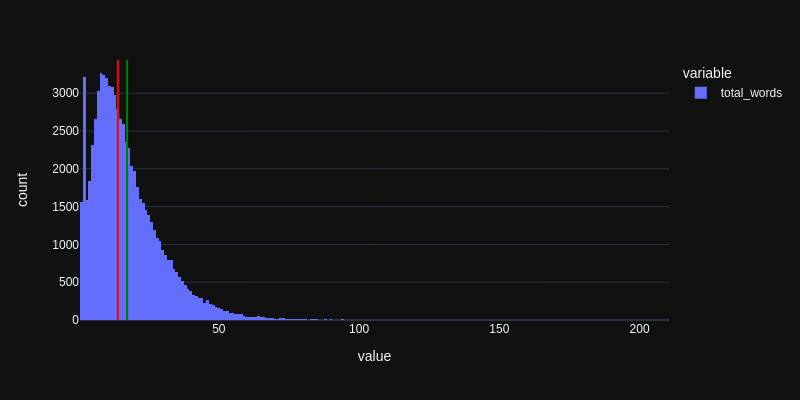

In [15]:
fig = px.histogram(train_df.total_words, template='plotly_dark')
fig.update_layout(autosize=False, width=800, height=400)
fig.add_vline(x=total_word_mean, line_color="green")
fig.add_vline(x=total_word_median, line_color="red")
fig.show('png')

In [16]:
sum(train_df.total_words < 50) / len(train_df)

0.9770705042095043

- On an average `17 words` used for single sentence.
- `97%` of the training data has length of sentence is below `50 words`.

#### NER Tags

In [17]:
all_tags = np.hstack(train_df.tags.values)
tag_count_df = pd.DataFrame(np.unique(all_tags, return_counts=True)).T
tag_count_df = tag_count_df.rename(columns={0:'tag', 1:'count'})
tag_count_df = tag_count_df.astype({'count':'int32'})

In [18]:
none_other_tag_count_df = tag_count_df[tag_count_df.tag != 'O']

In [19]:
none_other_tag_count_df['count'].sum()

149374

In total 150K ner tags.

In [20]:
unique_tags = none_other_tag_count_df.tag.apply(lambda x : re.sub("(B|I)\-", "", x)).unique()
print("Entity types:", len(unique_tags))
print(unique_tags)

Entity types: 18
['CARDINAL' 'DATE' 'EVENT' 'FAC' 'GPE' 'LANGUAGE' 'LAW' 'LOC' 'MONEY'
 'NORP' 'ORDINAL' 'ORG' 'PERCENT' 'PERSON' 'PRODUCT' 'QUANTITY' 'TIME'
 'WORK_OF_ART']


In [21]:
1 - tag_count_df[tag_count_df.tag == 'O']['count'] / tag_count_df['count'].sum()

36    0.114964
Name: count, dtype: float64

11% of dataset has ner tags.

In [22]:
begin_only_tag_count_df = none_other_tag_count_df[none_other_tag_count_df['tag'].str.startswith("B-")]

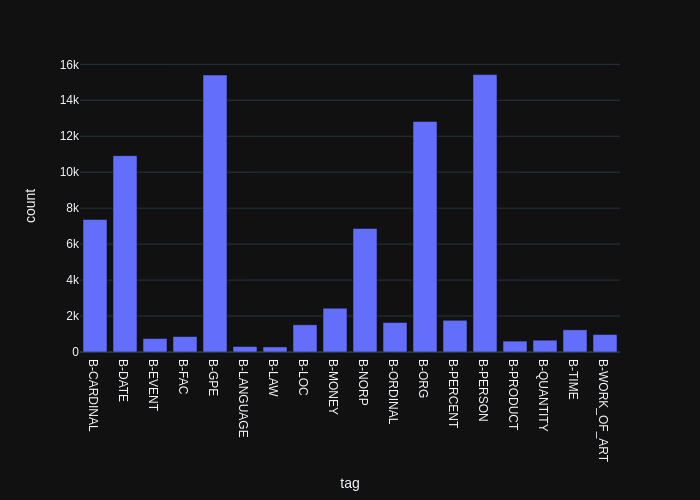

In [23]:
fig = px.bar(begin_only_tag_count_df, x='tag', y='count', template='plotly_dark')
fig.show('png')

An entity GPE, ORG and PERSON has around 14K ner tag.

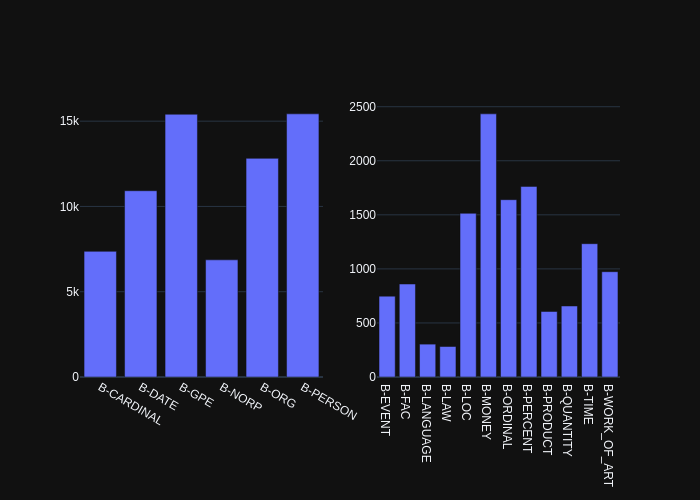

In [24]:
fig = make_subplots(rows=1, cols=2)

fig.append_trace(px.bar(begin_only_tag_count_df[begin_only_tag_count_df['count'] > 6000], x='tag', y='count')['data'][0], row=1, col=1)
fig.append_trace(px.bar(begin_only_tag_count_df[begin_only_tag_count_df['count'] < 6000], x='tag', y='count')['data'][0], row=1, col=2)

fig.update_layout(template='plotly_dark')

fig.show('png')

Few hunders of tags in LAW, LANGUAGE, EVENT, FAC, PRODUCT, QUALITY, TIME, WORK_OF_ART entity type.

#### NER Tag Word Cloud

In [25]:
all_tags = {}

def store_entity(tag,val):
    if val is not None:
        ls = all_tags.get(tag, [])
        ls.append(val)
        all_tags[tag] = ls

for i, row in train_df.iterrows():

    current_word, current_tag = None, None

    for w, t in zip(row['words'], row['tags']):

        if t.startswith("B-"):
            store_entity(current_tag, current_word)
            current_tag = t[2:]
            current_word = w
        elif t.startswith("I-") and current_tag == t[2:]:
            current_word += " " + w
        else:
            store_entity(current_tag, current_word)
            current_word, current_tag = None, None

    store_entity(current_tag, current_word)

    pass

>> WORD CLOUD: ORG


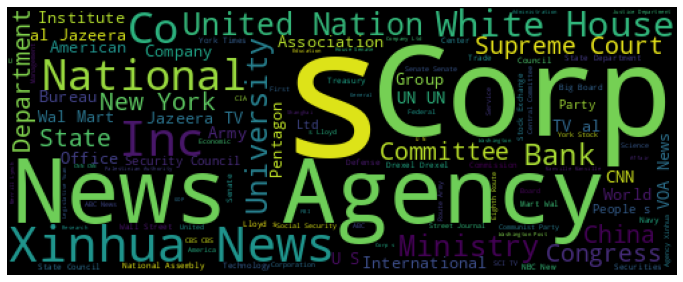

>> WORD CLOUD: WORK_OF_ART


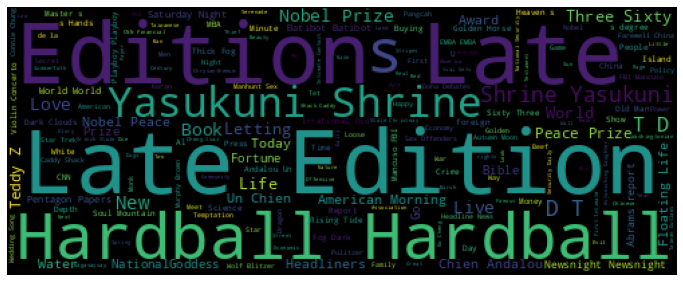

>> WORD CLOUD: LOC


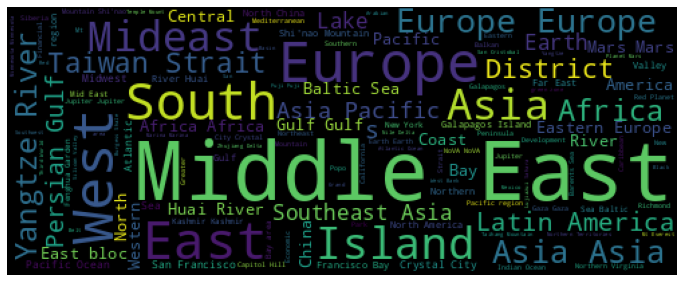

>> WORD CLOUD: CARDINAL


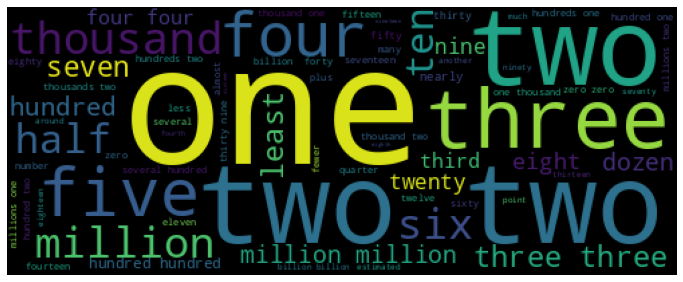

>> WORD CLOUD: EVENT


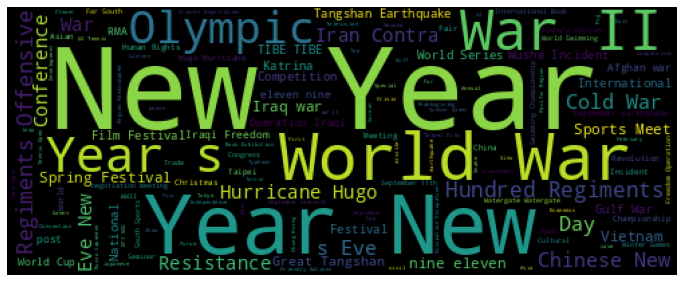

>> WORD CLOUD: NORP


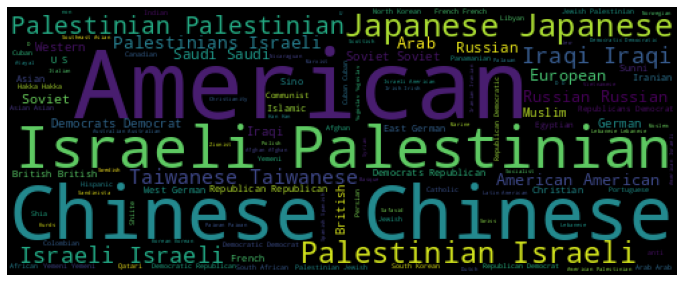

>> WORD CLOUD: GPE


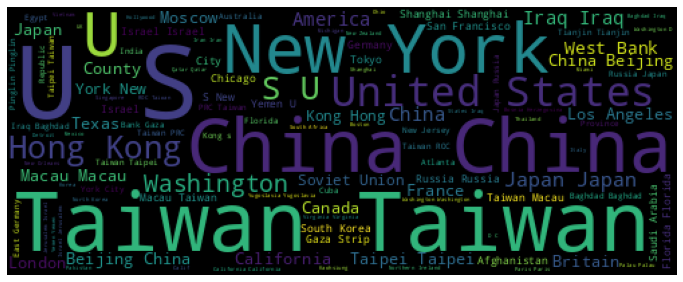

>> WORD CLOUD: DATE


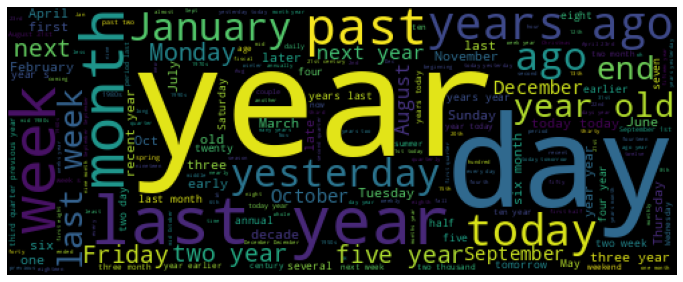

>> WORD CLOUD: PERSON


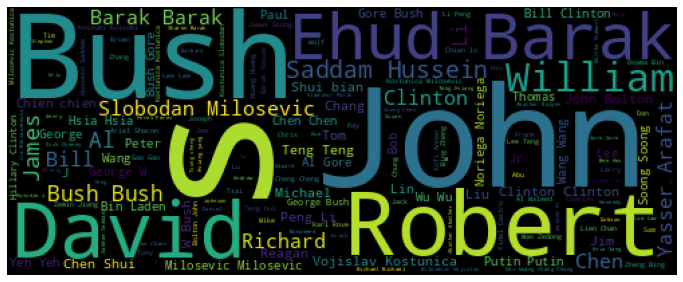

>> WORD CLOUD: FAC


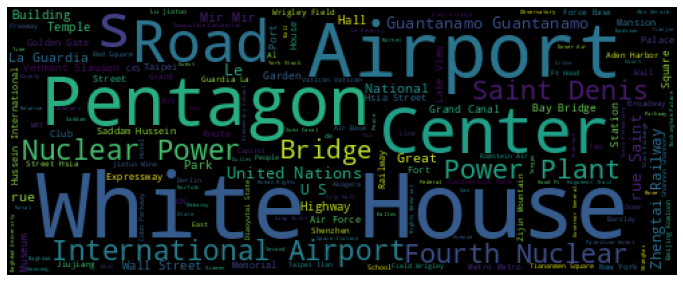

>> WORD CLOUD: QUANTITY


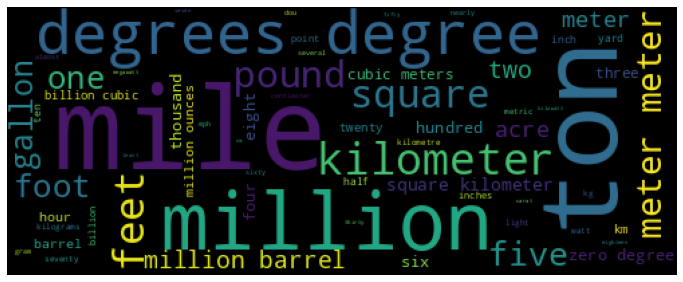

>> WORD CLOUD: ORDINAL


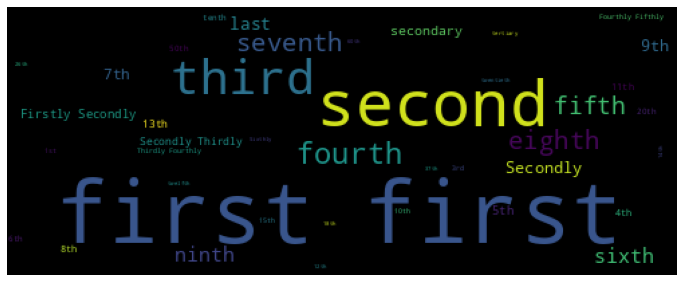

>> WORD CLOUD: TIME


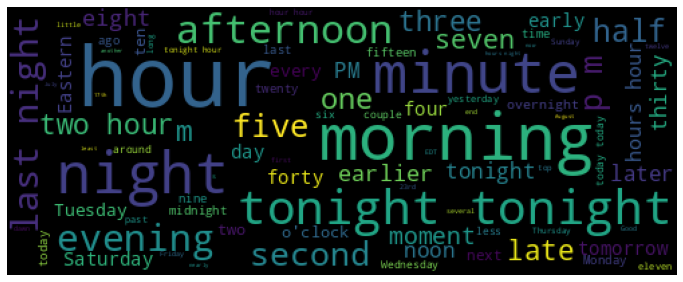

>> WORD CLOUD: PRODUCT


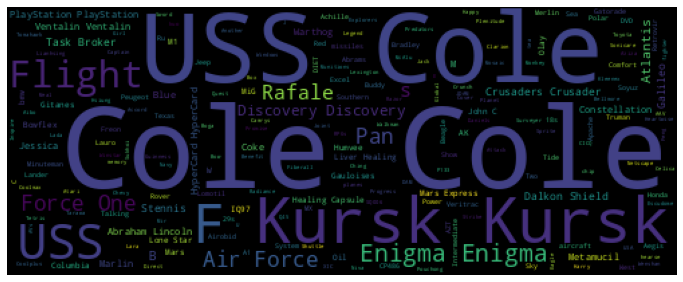

>> WORD CLOUD: PERCENT


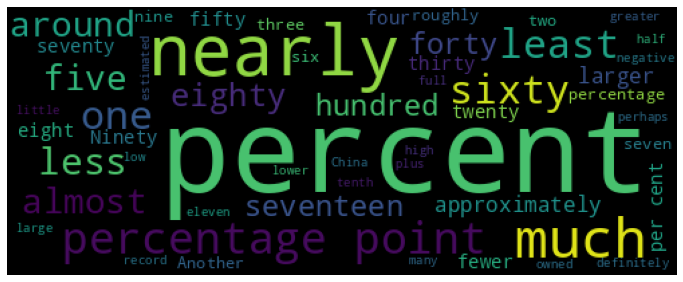

>> WORD CLOUD: MONEY


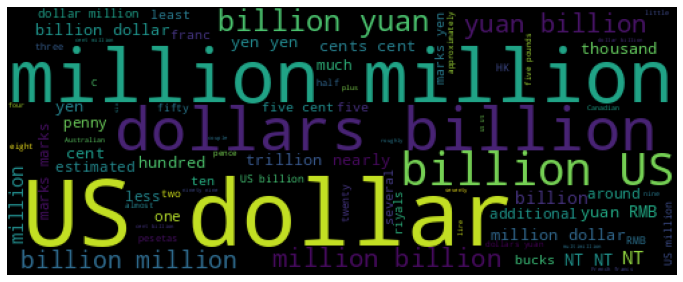

>> WORD CLOUD: LAW


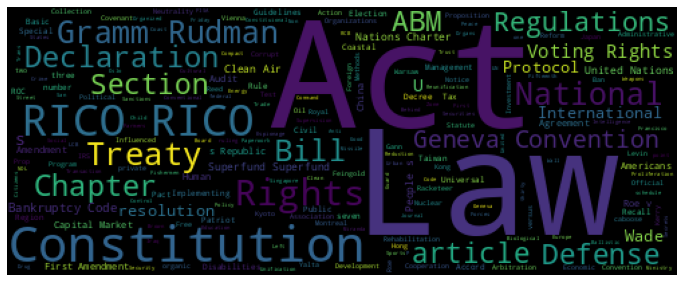

>> WORD CLOUD: LANGUAGE


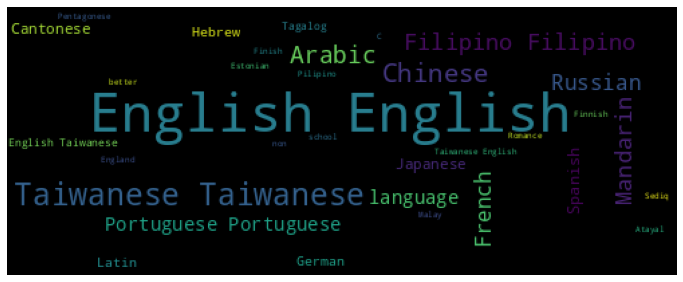

In [26]:
for k, v in all_tags.items():
    print(">> WORD CLOUD:", k)
    wordcloud = WordCloud(width = 500, height = 200).generate(" ".join(v))
    plt.figure(figsize=(12,8))
    plt.imshow(wordcloud)
    plt.axis("off")
    plt.show()

### Insights

Training: 75K samples <br>
Testing: 10k samples <br>
Entities : 18 <br>



- Word Analysis
    - 12 million words.
    - Near 220k words is 3 to 4 characters long. 
    - 74% of words is less than 5 characters long.
    - 97% of words is less than 10 characters long.
- Sentence Analysis
    - Average 17 words used for single sentence.
    - 97% of sentences has less than 50 words.
- NER Tags Analysis
    - 150K entity tags.
    - 11% of dataset is annotated.